In [72]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [8]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.3 MB 5.6 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.3 MB 8.4 MB/s eta 0:00:01
   ------------------------ --------------- 5.0/8.3 MB 9.4 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.3 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 9.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   - -------------------------------------- 1.3/36.7 MB 8.4 MB/s eta 0:00:05
   --- ------------------------------------ 3.4/36.7 MB 8.0 MB/s eta 0:00:05
   ----- ---------------------------------- 5.0/36.7 MB 7.9 MB/s eta 0:00:04
   ------- -------------------------------- 7.1/36.7 MB 8.4 MB/s eta 0:00:04
   --------- ------------------------------ 8.9/36.7 MB 8.8 MB/s eta 0:00:04
   ----------- ---------------------------- 10.5/36.7 MB 8.4 MB/s eta 0:00:04
   ------------- -


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [10]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [11]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

In [ ]:
plt.figure(figsize=(10,3))
plt.plot()

<Figure size 1000x300 with 0 Axes>

<Figure size 1000x300 with 0 Axes>

<Axes: xlabel='age', ylabel='Count'>

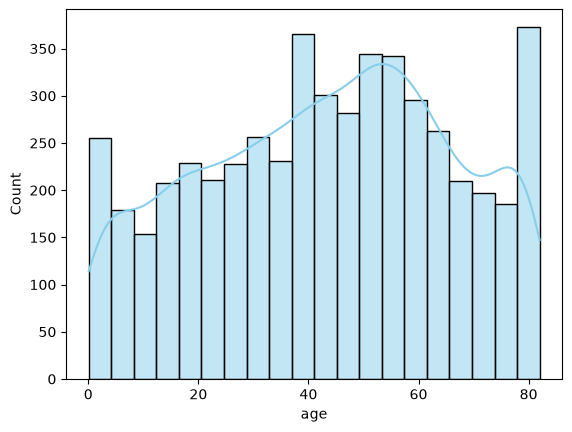

In [18]:
sns.histplot(data=df,kde=True,x="age",color="skyblue")




<Axes: xlabel='avg_glucose_level', ylabel='Count'>

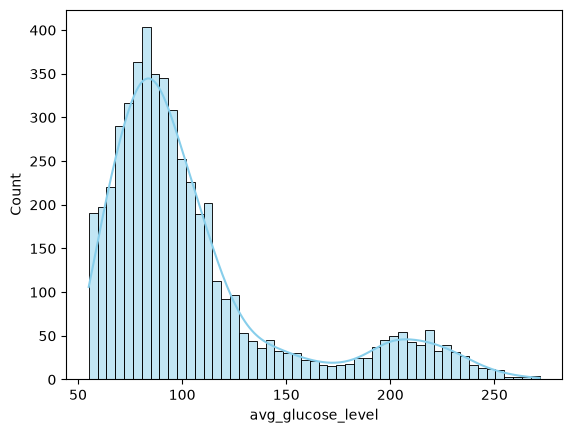

In [19]:
sns.histplot(data=df,kde=True,x="avg_glucose_level",color="skyblue")

<Axes: xlabel='bmi', ylabel='Count'>

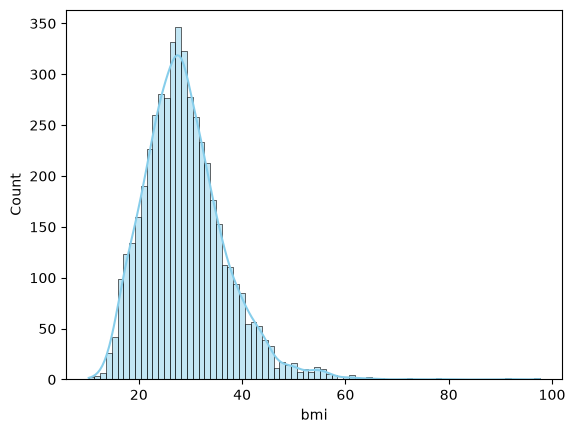

In [21]:
sns.histplot(data=df,kde=True,x="bmi",color="skyblue")

In [30]:
df=df[df["gender"] != "other"]

<Axes: xlabel='gender', ylabel='count'>

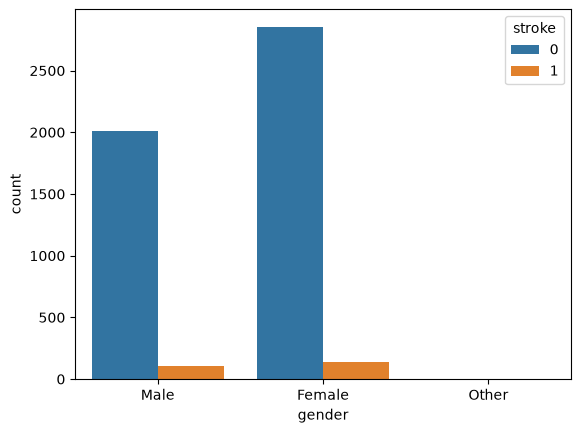

In [31]:
sns.countplot(data=df,x="gender",hue="stroke")

<Axes: xlabel='work_type', ylabel='count'>

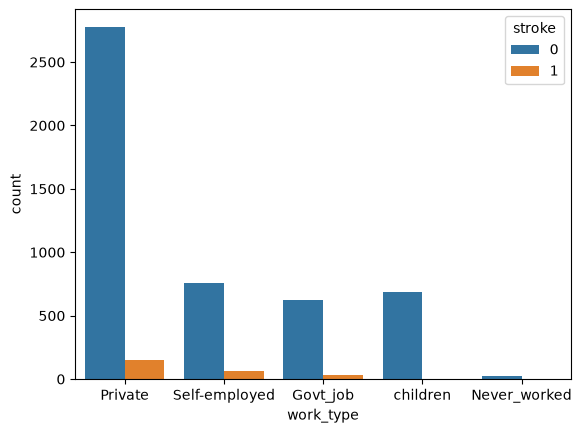

In [25]:
sns.countplot(data=df,x="work_type",hue="stroke")

<Axes: xlabel='smoking_status', ylabel='count'>

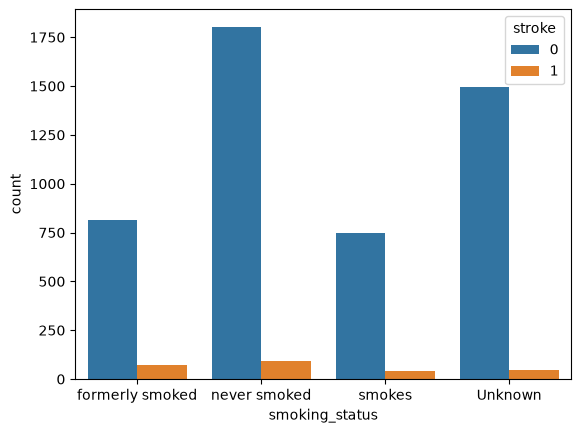

In [27]:
sns.countplot(data=df,x="smoking_status",hue="stroke")

In [32]:
mat=df.corr(numeric_only=True)

<Axes: >

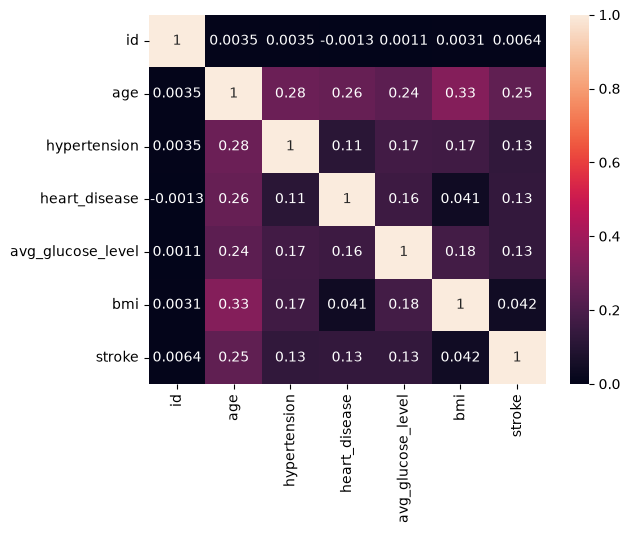

In [33]:
sns.heatmap(mat,annot=True)

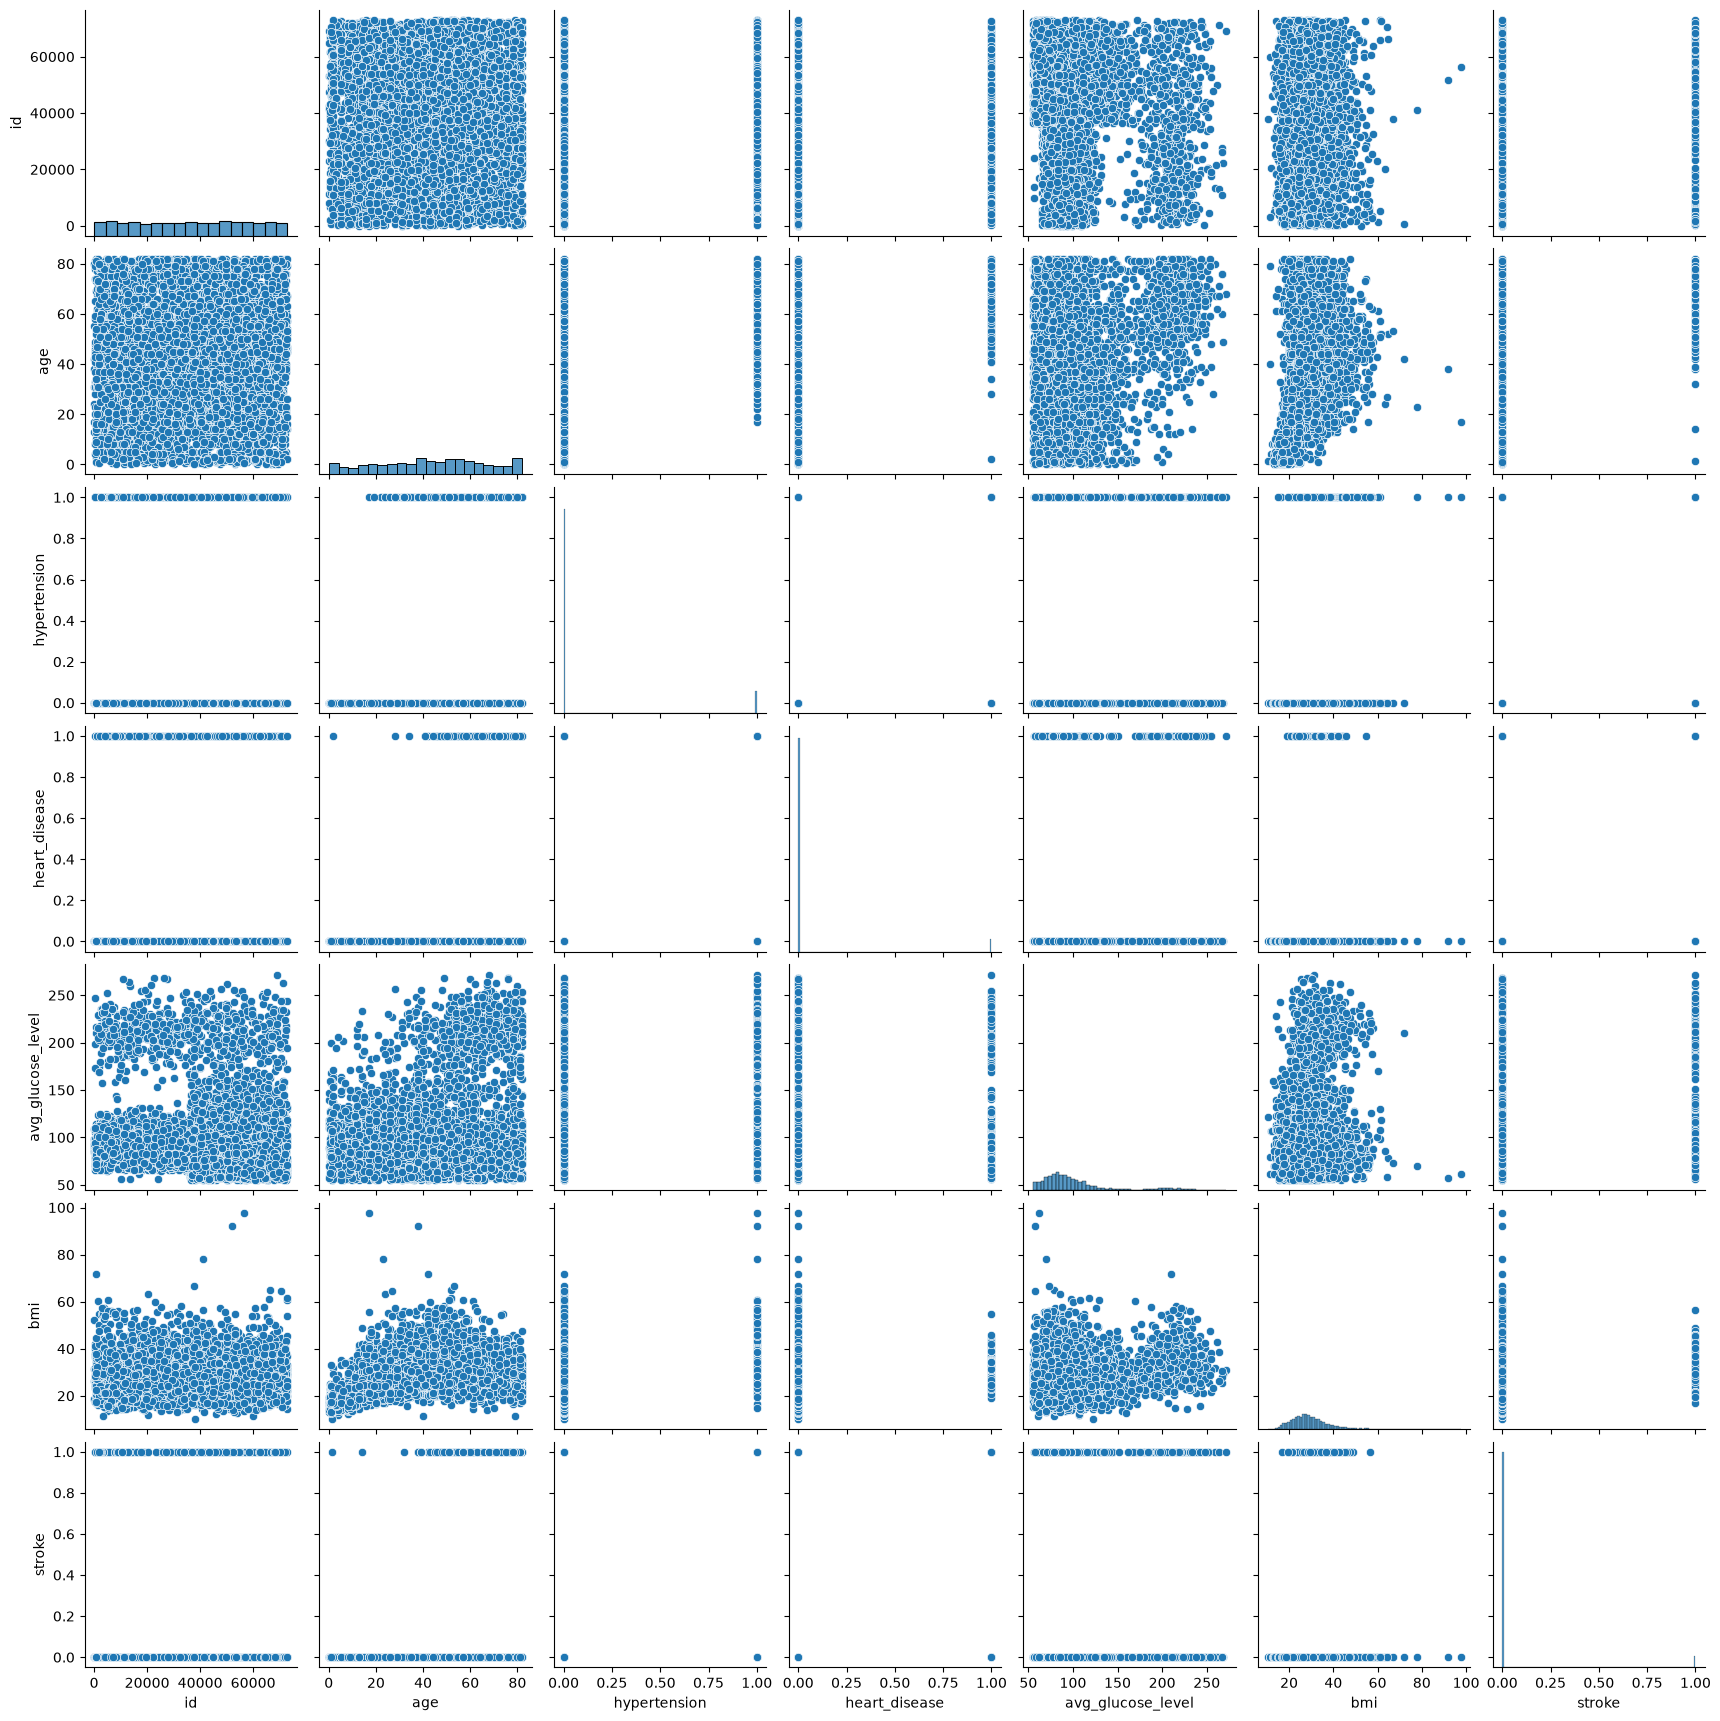

In [34]:
sns.pairplot(df)

In [73]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [74]:
df.drop_duplicates()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [75]:
df["bmi"]= df["bmi"].fillna(df["bmi"].mean())
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,28.893237,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.000000,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.600000,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.600000,formerly smoked,0


In [76]:
df.drop(["id"],axis=1)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,28.893237,never smoked,0
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.000000,never smoked,0
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.600000,never smoked,0
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.600000,formerly smoked,0


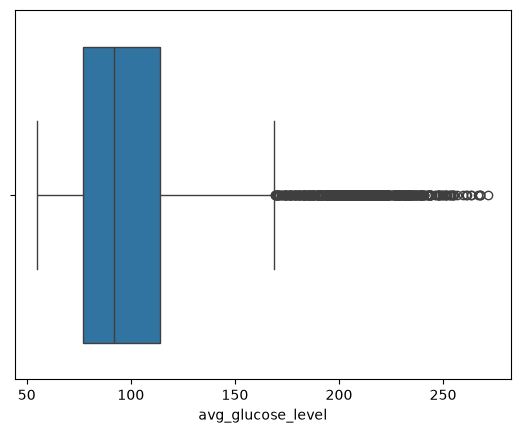

In [77]:
sns.boxplot(data=df,x="avg_glucose_level")
plt.show()

In [65]:
data={"gender","work_type","smoking_ststus","ever_married","Reridence_type"}
df=pd.DataFrame(data)
df

,0
0,smoking_ststus
1,gender
2,work_type
3,ever_married
4,Reridence_type


In [66]:
OneHotEncoder()

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent

In [78]:
x= df.drop(columns=["stroke"])
y= df["stroke"]

In [79]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(
    x , y,test_size=0.2,random_state=42,stratify=y
)

In [80]:
print("x_train shape:",x_train.shape)
print("x_test shape:",x_test.shape)
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)



x_train shape: (4088, 11)
x_test shape: (1022, 11)
y_train shape: (4088,)
y_test shape: (1022,)


In [81]:
from sklearn.preprocessing import MinMaxScaler

In [82]:
num_cols = ["age","avg_glucose_level","bmi"]

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train[num_cols]=scaler.fit_transform(x_train[num_cols])
x_test[num_cols]=scaler.transform(x_test[num_cols])

In [86]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True)*100)

stroke
0    3889
1     199
Name: count, dtype: int64
stroke
0    95.132094
1     4.867906
Name: proportion, dtype: float64


In [91]:
from imblearn.over_sampling import RandomOverSampler
ros =RandomOverSampler(random_state=42)
x_train_bal,y_train_bal=ros.fit_resample(x_train,y_train)
print(y_train_bal.value_counts())

stroke
0    3889
1    3889
Name: count, dtype: int64


In [ ]:
##conclusion 
## high-rish stroke patient persona
A high-risk stroke patient in this dataset is typically an older adult(commonly within the **40-80** age range)
with elevated blood glucose levels("avg_glucose_level")and higher body mass("bmi"around **30**).They are more likely to appear in active/adult categories such as **private**,**Self-employed**,
or **Govt_job** rather than "children" or "Never_worked", and may fall across smking categories such as **formerly smked**,
**never smoked**, or **smokes**.
## Summary of findings
- **Exploratory Analysis:**"countplots" and "boxplot" showed strong class imbalance in "stroke" across categories ("gender","work_type","smoking_ststus")
along with high/right-shifted values in "avg_glucose_level".
- **Data Cleaning :**Checked missing values("isnull().sum()",finding "201" missing values in "bmi"), handled missing values no remaining missing values,dropped duplicates and non_predictive columns ("id")
, and inspected "avg_glucose_level" outliers with a boxplot without removing them.
- **Transformation & Splitting :prepared features and target ("stroke"),split the data 80/20 with "random_state=42"("x_train",and,"y_test"of lenght "4088","x_test"and "y_test" of lenght"1022"),
and verified shapes.
- **Feature Scaling :** Scaled "age","avg_glucose_level",and "bmi" using "StandardScaler" fil on  training data only before transforming training and test sets to prevent data leakage.
- **Class Imbalance :** Addressed imbalance in "y_train"("0":"3889"/ ~"95.113%","1":"199"/~"4.87%") using "RandomOverSampler" on training data only, reaching "3889" samles per class